<a href="https://colab.research.google.com/github/Minetriforce/Gen_AI-TDs/blob/main/TP3_2_DDPM_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP3.2 — Implementing DDPM and Training Process

**Introduction to Deep Generative Models  **

For each practical exercise (TP), please work in groups of two or three. Then, create a private GitHub repository and add me (my GitHub is **arthur-75**) to your project.

In this exercise we will be training a Denoising Diffusion Probabilistic Model (DDPM).

> **Student note:** Complete all `xxx` placeholders and required definitions yourselves. This notebook preserves the unfinished code in the source. It refers to code from TP3.1 and external files such as `diffusion_utilities.py`, dataset `.npy` files, and model weights; they are not bundled here.

## 1. Set up

- Use the same network hyperparameters & diffusion hyperparameters of the previous exercise.
- Build your:
  - DDPM noise schedule
  - Context U-net
  - Function that removes the predicted noise
  - Sampling function

### Training hyperparameters

In [ ]:
from tqdm import tqdm
import torch
import os
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from diffusion_utilities import ResidualConvBlock, UnetUp, UnetDown, EmbedFC, plot_sample, CustomDataset, transform

# training hyperparameters
batch_size = 100
n_epoch = 32
lrate = 1e-3

### Reuse your implementation from TP3.1

Set up the same noise schedule, Context U-Net, DDPM denoising helper and sampler before training.

In [ ]:
# TODO (from TP3.1): Construct the DDPM noise schedule, Context U-Net,
# denoise_add_noise, sample_ddpm, device, timesteps, height, and save_dir.
# Do not solve this cell by copying an answer; complete using your own TP3.1 work.

## 2. Preparing the Dataset and Optimizer

- Load the dataset using a custom PyTorch Dataset.
- Wrap it in a DataLoader for batch processing.
- Define an Adam optimizer to update model parameters.
- Plot a few samples.

In [ ]:
# load dataset and construct optimizer
dataset = CustomDataset("./sprites_1788_16x16.npy",
                        "./sprite_labels_nc_1788_16x16.npy", transform, null_context=False)
dataloader = xxx(dataset, batch_size=batch_size, shuffle=True, num_workers=1)
optim = torch.optim.xxx(xxx.parameters(), lr=lrate)

def plot_sample_images(loader):
    images,_ = xxx(xxx(loader))
    plt.figure(figsize=(10, 5))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].permute(1, 2, 0).cpu().numpy())
        plt.axis("off")
    plt.tight_layout()
    plt.show()
plot_sample_images(xxx)

## 3. Perturbing Input Images

Since the model learns to remove noise, we must apply noise to the images during training.

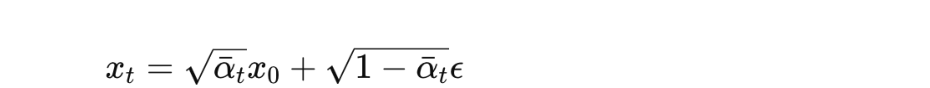

**Can you explain the components?**

- $x_t$ ...
- $x_0$ ...
- $\bar\alpha_t$ ...
- $\epsilon$ ...

In [ ]:
# helper function: perturbs an image to a specified noise level
def perturb_input(x, t, noise):
    return ab_t.sqrt()[t, None, None, None] * xxx + (1 - ab_t[t, None, None, None]) * xxx

## 4. Training Loop

The model is trained by predicting the noise added to the images.

1. Set the model to training mode.
2. Loop through epochs:
   - Adjust the learning rate for stability.
   - Loop through batches in the DataLoader:
     - Sample a batch of images $x$.
     - Perturb them by adding noise.
     - Pass them through the U-Net model to predict the noise.
     - Compute mean squared error (MSE) loss.
     - Perform backpropagation and optimizer updates.
3. Save the model periodically.

In [ ]:
# training without context code

# set into train mode
nn_model.xxx()
for ep in range(n_epoch):
    print(f'epoch {ep}')

    # linearly decay learning rate
    optim.param_groups[0]['lr'] = lrate*(1-ep/n_epoch)

    pbar = tqdm(xxx, mininterval=2 )
    for x, _ in pbar:   # x: images
        xxx.zero_grad()
        x = x.to(device)

        # perturb data
        noise = torch.randn_like(x)
        t = torch.randint(1, timesteps + 1, (x.shape[0],)).to(device)
        x_pert = xxx(x, t, noise)

        # use network to recover noise
        pred_noise = xxx(xxx, t / xxx)

        # loss is mean squared error between the predicted and true noise
        loss = F.mse_loss(xxx, xxx)
        loss.backward()

        optim.step()

    # save model periodically
    if ep%4==0 or ep == int(n_epoch-1):
        if not os.path.exists(save_dir):
            os.mkdir(save_dir)
        torch.save(nn_model.state_dict(), save_dir + f"model_{ep}.pth")
        print('saved model at ' + save_dir + f"model_{ep}.pth")

## 5. Model Evaluation and Sampling

After training, we load different model checkpoints and sample images.

**Evaluation steps**

1. Load model weights for a specific epoch.
2. Set the model to evaluation mode.
3. Generate and visualize samples using the trained model.

In [ ]:
# load in model weights and set to eval mode
nn_model.load_state_dict(torch.load(f"{save_dir}/model_0.pth", map_location=device))
nn_model.eval()
print("Loaded in Model")
# visualize samples
plt.clf()
samples, intermediate_ddpm = sample_ddpm(32)
animation_ddpm = plot_sample(intermediate_ddpm,32,4,save_dir, "ani_run", None, save=False)
HTML(animation_ddpm.to_jshtml())

**Exercise:** Now, plot for epoch 5, 10, 20 and 31 (models are provided on the drive). What is your observation?

In [ ]:
# TODO: Load checkpoints for epochs 5, 10, 20 and 31 and compare generated samples.

## 6. Building DDIM Denoising and Sampling Functions

In DDIM (Denoising Diffusion Implicit Model), we use a deterministic approach to remove noise step-by-step, rather than relying on stochastic diffusion like in DDPM. Below is an explanation of how we implement `denoise_ddim()` and `sample_ddim()`.

This function removes noise from a given image $x_t$ at timestep $t$, using the model’s predicted noise $\epsilon_\theta(x_t,t)$.

**We estimate the clean image $x_0$:**

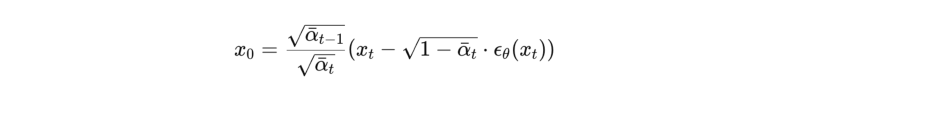

**Then, we compute the direction pointing to $x_t$:**

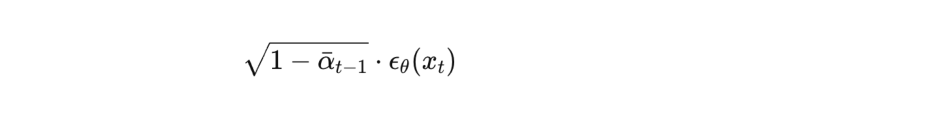

**Finally, we reconstruct $x_{t-1}$ as:**

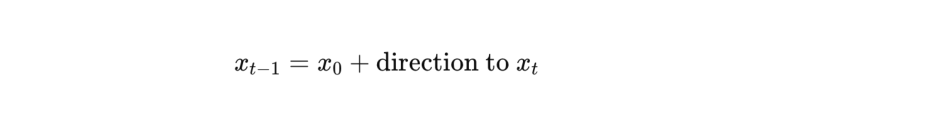

In [ ]:
# define sampling function for DDIM
# removes the noise using ddim
def denoise_ddim(xxx, xxx, xxx, xxx):
   ab = ab_t[t]
   ab_prev = ab_t[t_prev]

   x0_pred = ab_prev.sqrt() / ab.sqrt() * (x - (1 - ab).sqrt() * pred_noise)
   dir_xt = (1 - ab_prev).sqrt() * pred_noise

   return x0_pred + dir_xt

The next function generates images by iteratively applying the denoising function from pure noise $x_T$ to a final image $x_0$.

- We initialize random Gaussian noise $x_T \sim \mathcal{N}(0,I)$.
- **Iterative reverse diffusion:**
  - Denoise step-by-step from $x_T$ to $x_0$.
  - Instead of 1000+ steps (like DDPM), DDIM reduces this to ~20–50 steps.

In [ ]:
# sample quickly using DDIM
@torch.no_grad()
def sample_ddim(n_sample, n=20):
   # x_T ~ N(0, 1), sample initial noise
   samples = torch.randn(n_sample, 3, height, height).to(device)

   # array to keep track of generated steps for plotting
   intermediate = []
   step_size = timesteps // n
   for i in range(timesteps, 0, -step_size):
       print(f'sampling timestep {i:3d}', end='\r')

       # reshape time tensor
       t = torch.tensor([i / timesteps])[:, None, None, None].to(device)

       eps = nn_model(samples, t)    # predict noise e_(x_t,t)
       samples = denoise_ddim(samples, i, i - step_size, eps)
       intermediate.append(samples.detach().cpu().numpy())

   intermediate = np.stack(intermediate)
   return samples, intermediate
# visualize samples
plt.clf()
samples, intermediate = sample_ddim(32, n=25)
animation_ddim = plot_sample(intermediate,32,4,save_dir, "ani_run", None, save=False)
HTML(animation_ddim.to_jshtml())